# INF6243 – Projet de session : Détection de spam SMS
**Université du Québec en Outaouais – INF 6243 Techniques d'apprentissage**

**Objectif :** classer automatiquement des SMS en *spam* ou *ham* (message légitime) et comparer
5 algorithmes classiques (Naive Bayes, Régression logistique, SVM linéaire, Random Forest, KNN)
avec un modèle d'apprentissage profond (BiLSTM).

**Plan du notebook**
1. Chargement des données
2. Analyse exploratoire (EDA)
3. Prétraitement et séparation train / validation / test
4. Modèles classiques : réglage des hyperparamètres (GridSearchCV, validation croisée 5 plis)
5. Apprentissage profond : BiLSTM
6. Comparaison et sélection du modèle (validation)
7. Évaluation finale sur l'ensemble de test
8. Courbes d'apprentissage
9. Importance des attributs
10. Analyse des erreurs
11. Conclusion

In [1]:
import time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer

from preprocessing import load_data, clean_text, add_meta_features, split_data, RANDOM_STATE
from models import get_classical_models, get_scores, Vocab, train_bilstm, predict_bilstm
import utils as U

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
DATA = Path("../Data/SMSSpamCollection")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
np.random.seed(RANDOM_STATE)

## 1. Chargement des données
Source : *SMS Spam Collection* (UCI Machine Learning Repository, Almeida et al., 2011).
Fichier TSV à deux colonnes : étiquette (`ham` / `spam`) et texte brut du message.

In [2]:
df = load_data(DATA)
print("Dimensions :", df.shape)
df.head()

Dimensions : (5574, 3)


,label,message,y
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


## 2. Analyse exploratoire
### 2.1 Valeurs manquantes et doublons

In [3]:
print("Valeurs manquantes par colonne :\n", df.isna().sum(), sep="")
n_dup = df.duplicated(subset="message").sum()
print(f"\nMessages en double : {n_dup} ({n_dup / len(df):.1%})")
print(df[df.duplicated(subset='message', keep=False)].groupby('label').size().rename('lignes concernées'))

Valeurs manquantes par colonne :
label      0
message    0
y          0
dtype: int64

Messages en double : 403 (7.2%)
label
ham     503
spam    181
Name: lignes concernées, dtype: int64


### 2.2 Distribution des classes

          n     %
label            
ham    4827  86.6
spam    747  13.4


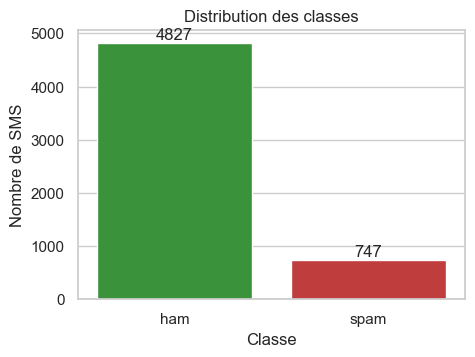

In [4]:
counts = df["label"].value_counts()
print(pd.DataFrame({"n": counts, "%": (counts / len(df) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="label", hue="label", order=["ham", "spam"], ax=ax, legend=False,
              palette={"ham": "tab:green", "spam": "tab:red"})
for c in ax.containers: ax.bar_label(c)
ax.set(title="Distribution des classes", xlabel="Classe", ylabel="Nombre de SMS")
save(fig, "01_distribution_classes"); plt.show()

Le jeu de données est **déséquilibré** (≈ 13 % de spam). Un classificateur qui prédit toujours
*ham* obtiendrait déjà ≈ 87 % d'accuracy : l'accuracy seule est donc trompeuse.
Nous utiliserons le **F1-score de la classe spam** comme métrique principale (sélection des
hyperparamètres et du modèle), complété par la précision, le rappel et l'AUC.

### 2.3 Statistiques descriptives (attributs dérivés du texte)

In [5]:
dfm = add_meta_features(df)
meta = ["n_chars", "n_words", "n_digits", "n_upper", "upper_ratio", "n_exclam",
        "has_url", "has_money", "has_phone"]
dfm.groupby("label")[meta].describe().T.round(2)

label                ham    spam
n_chars   count  4827.00  747.00
          mean     71.47  138.68
          std      58.33   28.87
          min       2.00   13.00
          25%      33.00  133.00
...                  ...     ...
has_phone min       0.00    0.00
          25%       0.00    1.00
          50%       0.00    1.00
          75%       0.00    1.00
          max       1.00    1.00

[72 rows x 2 columns]

In [6]:
dfm.groupby("label")[meta].mean().T.round(3).rename_axis("attribut (moyenne)")

label,ham,spam
attribut (moyenne),,
n_chars,71.472,138.676
n_words,14.304,23.912
n_digits,0.305,15.813
n_upper,4.098,15.470
upper_ratio,0.058,0.111
n_exclam,0.177,0.730
has_url,0.004,0.186
has_money,0.003,0.539
has_phone,0.001,0.756


### 2.4 Visualisations : longueur, chiffres, majuscules

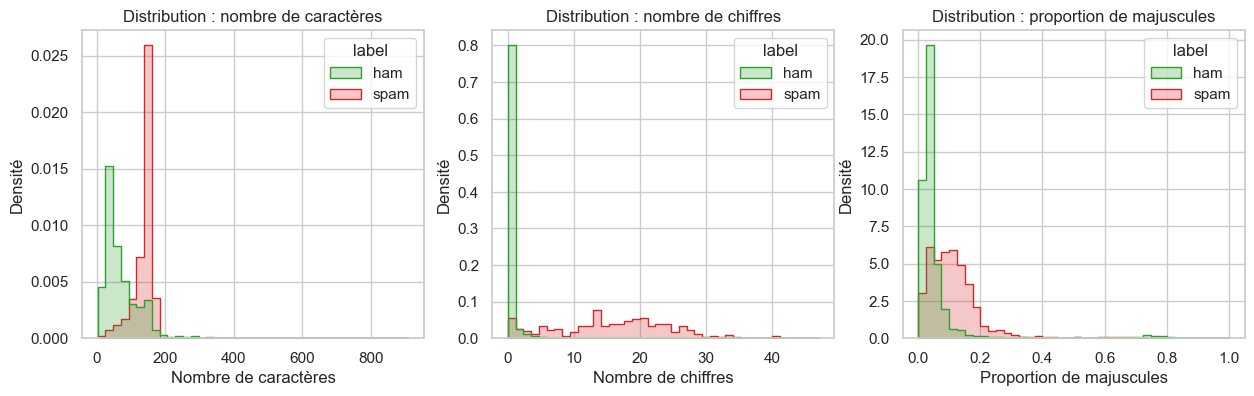

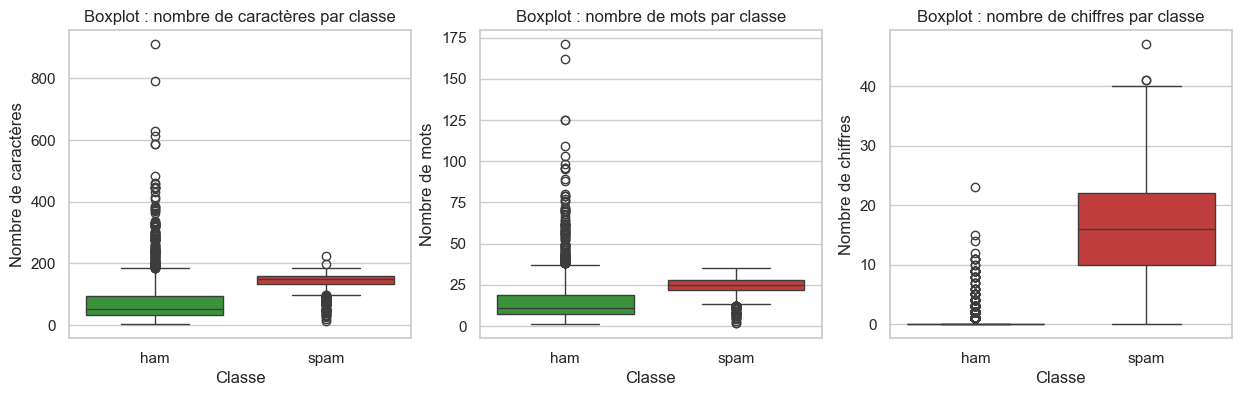

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, lab in zip(axes, ["n_chars", "n_digits", "upper_ratio"],
                        ["Nombre de caractères", "Nombre de chiffres", "Proportion de majuscules"]):
    sns.histplot(data=dfm, x=col, hue="label", bins=40, stat="density", common_norm=False,
                 element="step", ax=ax, palette={"ham": "tab:green", "spam": "tab:red"})
    ax.set(title=f"Distribution : {lab.lower()}", xlabel=lab, ylabel="Densité")
save(fig, "02_histogrammes"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, lab in zip(axes, ["n_chars", "n_words", "n_digits"],
                        ["Nombre de caractères", "Nombre de mots", "Nombre de chiffres"]):
    sns.boxplot(data=dfm, x="label", y=col, hue="label", ax=ax, legend=False,
                palette={"ham": "tab:green", "spam": "tab:red"})
    ax.set(title=f"Boxplot : {lab.lower()} par classe", xlabel="Classe", ylabel=lab)
save(fig, "03_boxplots"); plt.show()

### 2.5 Corrélations entre attributs

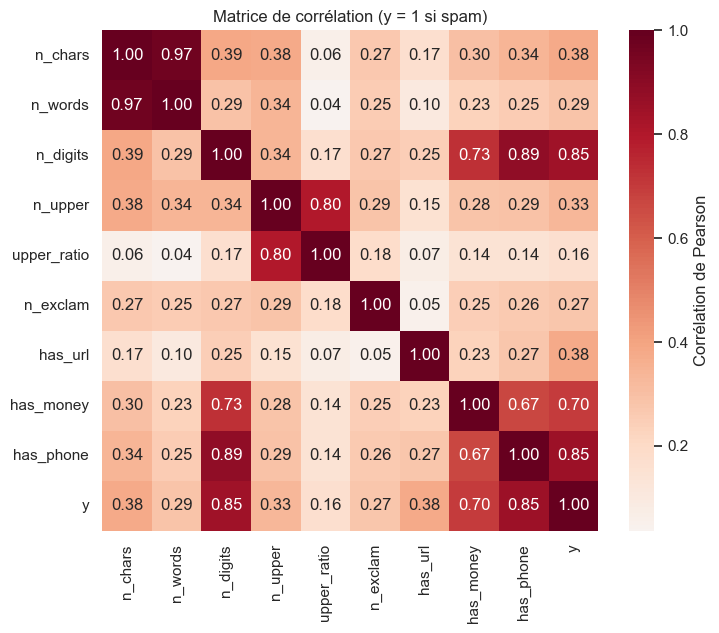

has_phone      0.851
n_digits       0.845
has_money      0.696
n_chars        0.383
has_url        0.377
n_upper        0.332
n_words        0.287
n_exclam       0.274
upper_ratio    0.164
Name: y, dtype: float64


In [8]:
corr = dfm[meta + ["y"]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Corrélation de Pearson"})
ax.set_title("Matrice de corrélation (y = 1 si spam)")
save(fig, "04_correlations"); plt.show()
print(corr["y"].drop("y").sort_values(ascending=False).round(3))

### 2.6 Mots les plus fréquents par classe (après nettoyage, sans mots vides)

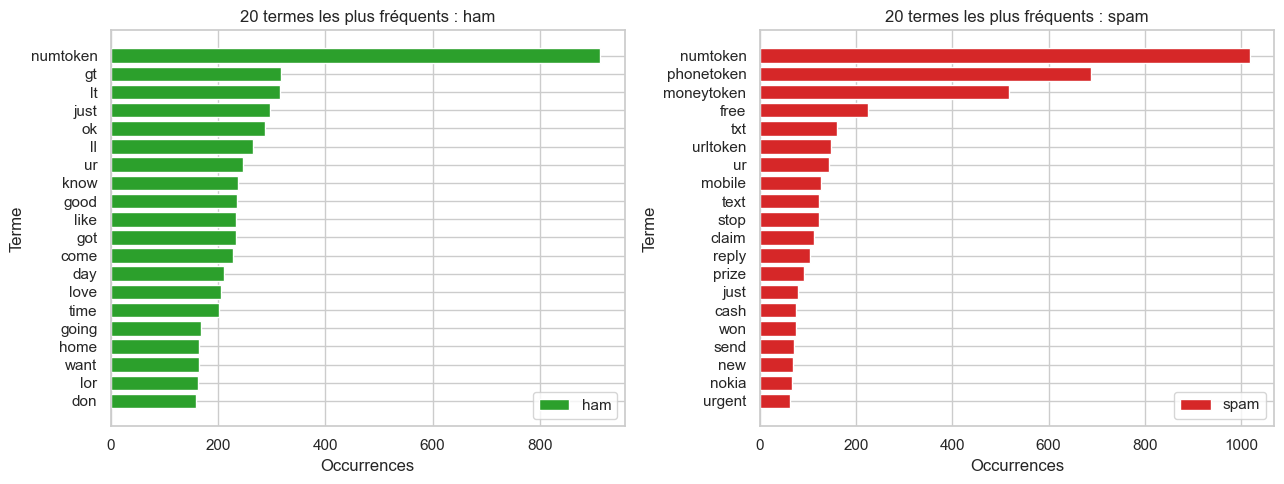

In [9]:
df["clean"] = df["message"].map(clean_text)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, lab, col in zip(axes, ["ham", "spam"], ["tab:green", "tab:red"]):
    cv = CountVectorizer(stop_words="english")
    X = cv.fit_transform(df.loc[df.label == lab, "clean"])
    freq = pd.Series(np.asarray(X.sum(0)).ravel(), index=cv.get_feature_names_out()).nlargest(20)
    ax.barh(freq.index[::-1], freq.values[::-1], color=col, label=lab)
    ax.set(title=f"20 termes les plus fréquents : {lab}", xlabel="Occurrences", ylabel="Terme")
    ax.legend()
plt.tight_layout(); save(fig, "05_mots_frequents"); plt.show()

## 3. Prétraitement
1. **Nettoyage** : minuscules ; URLs, courriels, montants, numéros de téléphone et nombres remplacés
   par des jetons (`urltoken`, `moneytoken`, `phonetoken`, …) ; ponctuation retirée sauf `!`.
2. **Doublons** : supprimés *avant* la séparation, sinon un même SMS pourrait se retrouver à la
   fois dans l'entraînement et le test (fuite de données → scores optimistes).
3. **Valeurs manquantes** : aucune (vérifié en 2.1).
4. **Encodage** : la cible est encodée 0/1 ; le texte est vectorisé par **TF-IDF** (dans les
   pipelines, ajusté uniquement sur les données d'entraînement de chaque pli) pour les modèles
   classiques, et par **indices de vocabulaire** pour le BiLSTM.
5. **Normalisation** : TF-IDF applique une normalisation L2 par document (équivalent d'une
   standardisation pour le texte) ; `sublinear_tf` atténue les mots répétés.
6. **Séparation stratifiée** 70 % / 15 % / 15 % (train / validation / test).

In [10]:
for m in df["message"].sample(4, random_state=1):
    print("BRUT  :", m); print("PROPRE:", clean_text(m)); print()

BRUT  : Looks like u wil b getting a headstart im leaving here bout 2.30ish but if u r desperate for my company I could head in earlier-we were goin to meet in rummer.
PROPRE: looks like u wil b getting a headstart im leaving here bout numtoken 30ish but if u r desperate for my company i could head in earlier we were goin to meet in rummer

BRUT  : I noe la... U wana pei bf oso rite... K lor, other days den...
PROPRE: i noe la u wana pei bf oso rite k lor other days den

BRUT  : 2mro i am not coming to gym machan. Goodnight.
PROPRE: 2mro i am not coming to gym machan goodnight

BRUT  : Todays Vodafone numbers ending with 4882 are selected to a receive a £350 award. If your number matches call 09064019014 to receive your £350 award.
PROPRE: todays vodafone numbers ending with numtoken are selected to a receive a moneytoken award if your number matches call phonetoken to receive your moneytoken award



In [11]:
data = df.drop_duplicates(subset="message").reset_index(drop=True)
print(f"Après suppression des doublons : {len(data)} SMS")
train, val, test = split_data(data)
split_info = pd.DataFrame({s: {"n": len(d), "% spam": round(d.y.mean() * 100, 2)}
                           for s, d in [("train", train), ("validation", val), ("test", test)]}).T
split_info

Après suppression des doublons : 5171 SMS


,n,% spam
train,3619.0,12.63
validation,776.0,12.63
test,776.0,12.63


In [12]:
X_tr, y_tr = train["clean"].to_numpy(dtype=object), train["y"].to_numpy()
X_va, y_va = val["clean"].to_numpy(dtype=object), val["y"].to_numpy()
X_te, y_te = test["clean"].to_numpy(dtype=object), test["y"].to_numpy()
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}

## 4. Modèles classiques

| Modèle | Fonctionnement | Justification pour le spam SMS |
|---|---|---|
| **Naive Bayes multinomial** | Applique la règle de Bayes en supposant les mots indépendants sachant la classe ; P(mot \| classe) estimée par fréquences lissées (paramètre `alpha`). | Référence historique du filtrage de spam ; très rapide, robuste sur petits corpus et vecteurs creux. |
| **Régression logistique** | Modèle linéaire : P(spam) = σ(w·x + b), poids appris par maximum de vraisemblance avec régularisation L2 (`C`). | Fournit des probabilités calibrées et des coefficients interprétables (quels mots indiquent le spam). |
| **SVM linéaire** | Cherche l'hyperplan qui maximise la marge entre les classes ; `C` règle le compromis marge / erreurs. | Excellent en haute dimension et sur données creuses (TF-IDF ≈ 10⁴ dimensions). |
| **Random Forest** | Ensemble d'arbres de décision entraînés sur des échantillons bootstrap et des sous-ensembles d'attributs ; vote majoritaire. | Capture des interactions non linéaires entre termes ; fournit l'importance des attributs. |
| **KNN** | Attribue la classe majoritaire parmi les *k* messages d'entraînement les plus proches (distance cosinus sur TF-IDF). | Méthode non paramétrique de référence ; montre les limites d'une approche par similarité en haute dimension. |

**Protocole** : pour chaque modèle, `GridSearchCV` avec validation croisée **stratifiée à 5 plis** sur
l'ensemble d'entraînement, critère de sélection = **F1 (spam)**. Le modèle réajusté sur tout
l'entraînement est ensuite évalué sur la validation.

In [13]:
models = get_classical_models()
best_models, cv_rows, cv_f1_folds, val_rows, grid_info = {}, {}, {}, {}, {}

for name, (pipe, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit="f1", n_jobs=-1)
    gs.fit(X_tr, y_tr)
    dt = time.time() - t0
    i = gs.best_index_
    r = gs.cv_results_
    best_models[name] = gs.best_estimator_
    cv_rows[name] = {f"CV {k} (moy)": r[f"mean_test_{k}"][i] for k in SCORING} | \
                    {"CV f1 (écart-type)": r["std_test_f1"][i]}
    cv_f1_folds[name] = [r[f"split{k}_test_f1"][i] for k in range(5)]
    grid_info[name] = {"combinaisons testées": len(r["params"]), "temps (s)": round(dt, 1),
                       "meilleurs hyperparamètres": gs.best_params_}
    pred = gs.predict(X_va)
    val_rows[name] = U.compute_metrics(y_va, pred, get_scores(gs.best_estimator_, X_va))
    print(f"{name:22s} F1-CV={r['mean_test_f1'][i]:.4f}  ({dt:.1f}s)  {gs.best_params_}")

Naive Bayes            F1-CV=0.9467  (10.4s)  {'clf__alpha': 0.05, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}


Régression logistique  F1-CV=0.9570  (2.4s)  {'clf__C': 100, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}


SVM linéaire           F1-CV=0.9634  (2.0s)  {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}


Random Forest          F1-CV=0.9299  (17.5s)  {'clf__class_weight': None, 'clf__max_depth': None, 'clf__n_estimators': 200}


KNN                    F1-CV=0.9312  (1.3s)  {'clf__n_neighbors': 15, 'clf__weights': 'distance'}


In [14]:
pd.DataFrame(grid_info).T

,combinaisons testées,temps (s),meilleurs hyperparamètres
Naive Bayes,20,10.4,"{'clf__alpha': 0.05, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}"
Régression logistique,16,2.4,"{'clf__C': 100, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}"
SVM linéaire,16,2.0,"{'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}"
Random Forest,8,17.5,"{'clf__class_weight': None, 'clf__max_depth': None, 'clf__n_estimators': 200}"
KNN,10,1.3,"{'clf__n_neighbors': 15, 'clf__weights': 'distance'}"


In [15]:
pd.DataFrame(cv_rows).T.round(4)

,CV accuracy (moy),CV precision (moy),CV recall (moy),CV f1 (moy),CV f1 (écart-type)
Naive Bayes,0.9870,0.9812,0.9147,0.9467,0.0140
Régression logistique,0.9892,0.9645,0.9496,0.9570,0.0082
SVM linéaire,0.9909,0.9753,0.9519,0.9634,0.0110
Random Forest,0.9834,0.9950,0.8730,0.9299,0.0113
KNN,0.9837,0.9950,0.8753,0.9312,0.0149


## 5. Apprentissage profond : BiLSTM

**Fonctionnement** : chaque mot est converti en vecteur dense (*embedding* appris, dim. 64).
Un LSTM **bidirectionnel** lit la séquence dans les deux sens et produit un état caché par mot ;
un *max-pooling* temporel retient les signaux les plus forts, puis une couche linéaire + sigmoïde
donne P(spam). Perte : entropie croisée binaire **pondérée** (`pos_weight` ≈ 6.6) pour compenser
le déséquilibre. Optimiseur Adam, *dropout*, arrêt précoce (patience = 3) sur la perte de validation.

**Justification** : contrairement au TF-IDF (sac de mots), le LSTM tient compte de l'**ordre des mots**
et du contexte (« call now to claim » vs « I'll call you now »).

**Réglage des hyperparamètres** : recherche sur grille (taille cachée × taux d'apprentissage ×
dropout) évaluée sur l'ensemble de validation, puis validation croisée 5 plis de la meilleure
configuration sur l'entraînement pour une comparaison équitable avec les modèles classiques.

In [16]:
import itertools, torch
torch.set_num_threads(4)
vocab = Vocab(X_tr, min_freq=2)
MAXLEN = 60
print("Taille du vocabulaire :", len(vocab))
lens = [len(t.split()) for t in X_tr]
print(f"Longueur des SMS (mots) : médiane={np.median(lens):.0f}, 95e centile={np.percentile(lens, 95):.0f}"
      f" -> séquences tronquées/complétées à {MAXLEN}")
S_tr, S_va, S_te = (vocab.encode(x, MAXLEN) for x in (X_tr, X_va, X_te))

Taille du vocabulaire : 2977
Longueur des SMS (mots) : médiane=13, 95e centile=34 -> séquences tronquées/complétées à 60


In [17]:
from sklearn.metrics import f1_score
dl_grid = {"hidden": [32, 64], "lr": [1e-3, 3e-3], "dropout": [0.2, 0.5]}
dl_res = []
for h, lr, dp in itertools.product(*dl_grid.values()):
    t0 = time.time()
    m, hist = train_bilstm(S_tr, y_tr, S_va, y_va, len(vocab), hidden=h, lr=lr, dropout=dp, epochs=20)
    p, pred = predict_bilstm(m, S_va)
    dl_res.append({"hidden": h, "lr": lr, "dropout": dp, "epochs": hist["best_epoch"],
                   "F1 val": f1_score(y_va, pred), "temps (s)": round(time.time() - t0, 1)})
dl_res = pd.DataFrame(dl_res).sort_values("F1 val", ascending=False)
dl_res.round(4)

,hidden,lr,dropout,epochs,F1 val,temps (s)
2,32,0.003,0.2,5,0.9505,9.3
7,64,0.003,0.5,7,0.9463,21.3
4,64,0.001,0.2,8,0.9412,22.6
0,32,0.001,0.2,7,0.9360,14.0
3,32,0.003,0.5,5,0.9353,9.2
6,64,0.003,0.2,6,0.9275,18.7
5,64,0.001,0.5,10,0.9231,27.2
1,32,0.001,0.5,5,0.9223,9.2


Meilleure configuration : {'hidden': 32, 'lr': 0.003, 'dropout': 0.2}


epoch  1  train_loss=0.7413  val_loss=0.2458  val_acc=0.9755  (2.1s)


epoch  2  train_loss=0.2052  val_loss=0.1658  val_acc=0.9820  (1.1s)


epoch  3  train_loss=0.0910  val_loss=0.1589  val_acc=0.9536  (1.4s)


epoch  4  train_loss=0.0537  val_loss=0.1538  val_acc=0.9781  (1.6s)


epoch  5  train_loss=0.0307  val_loss=0.1386  val_acc=0.9871  (1.6s)


epoch  6  train_loss=0.0184  val_loss=0.1397  val_acc=0.9845  (1.5s)


epoch  7  train_loss=0.0101  val_loss=0.1620  val_acc=0.9884  (1.5s)


epoch  8  train_loss=0.0062  val_loss=0.1520  val_acc=0.9832  (1.4s)


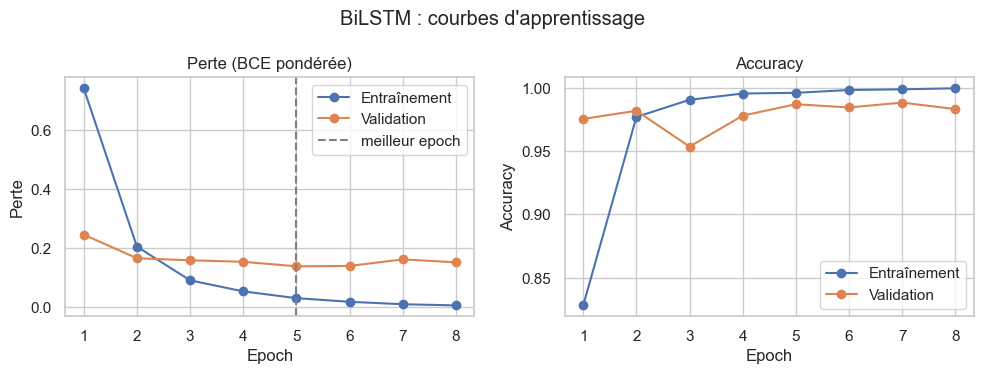

In [18]:
best_dl = dl_res.iloc[0][["hidden", "lr", "dropout"]].to_dict()
best_dl = {"hidden": int(best_dl["hidden"]), "lr": float(best_dl["lr"]), "dropout": float(best_dl["dropout"])}
print("Meilleure configuration :", best_dl)
bilstm, hist = train_bilstm(S_tr, y_tr, S_va, y_va, len(vocab), epochs=20, verbose=True, **best_dl)
fig = U.plot_dl_history(hist); save(fig, "06_bilstm_historique"); plt.show()

In [19]:
# Validation croisée 5 plis (le vocabulaire est reconstruit sur chaque pli d'entraînement
# et 10 % du pli d'entraînement sert à l'arrêt précoce -> aucun accès au pli évalué)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
folds = []
for k, (a, b) in enumerate(CV.split(X_tr, y_tr)):
    a_fit, a_es = train_test_split(a, test_size=0.1, stratify=y_tr[a], random_state=RANDOM_STATE)
    v = Vocab(X_tr[a_fit], min_freq=2)
    m, _ = train_bilstm(v.encode(X_tr[a_fit], MAXLEN), y_tr[a_fit], v.encode(X_tr[a_es], MAXLEN),
                        y_tr[a_es], len(v), epochs=20, **best_dl)
    _, pr = predict_bilstm(m, v.encode(X_tr[b], MAXLEN))
    folds.append({"accuracy": accuracy_score(y_tr[b], pr), "precision": precision_score(y_tr[b], pr),
                  "recall": recall_score(y_tr[b], pr), "f1": f1_score(y_tr[b], pr)})
folds = pd.DataFrame(folds)
cv_rows["BiLSTM"] = {f"CV {k} (moy)": folds[k].mean() for k in SCORING} | {"CV f1 (écart-type)": folds["f1"].std(ddof=0)}
cv_f1_folds["BiLSTM"] = folds["f1"].tolist()
p_va, pred_va = predict_bilstm(bilstm, S_va)
val_rows["BiLSTM"] = U.compute_metrics(y_va, pred_va, p_va)
folds.round(4)

,accuracy,precision,recall,f1
0,0.9724,0.8515,0.9451,0.8958
1,0.9820,0.9333,0.9231,0.9282
2,0.9848,0.9451,0.9348,0.9399
3,0.9807,0.8980,0.9565,0.9263
4,0.9779,0.9121,0.9121,0.9121


## 6. Comparaison et sélection du modèle
La sélection se fait sur la **validation croisée** et l'**ensemble de validation** ;
l'ensemble de test n'est utilisé qu'une seule fois, à l'étape 7.

In [20]:
cv_df = pd.DataFrame(cv_rows).T.rename_axis("Modèle")
cv_df.sort_values("CV f1 (moy)", ascending=False).round(4)

,CV accuracy (moy),CV precision (moy),CV recall (moy),CV f1 (moy),CV f1 (écart-type)
Modèle,,,,,
SVM linéaire,0.9909,0.9753,0.9519,0.9634,0.0110
Régression logistique,0.9892,0.9645,0.9496,0.9570,0.0082
Naive Bayes,0.9870,0.9812,0.9147,0.9467,0.0140
KNN,0.9837,0.9950,0.8753,0.9312,0.0149
Random Forest,0.9834,0.9950,0.8730,0.9299,0.0113
BiLSTM,0.9796,0.9080,0.9343,0.9205,0.0152


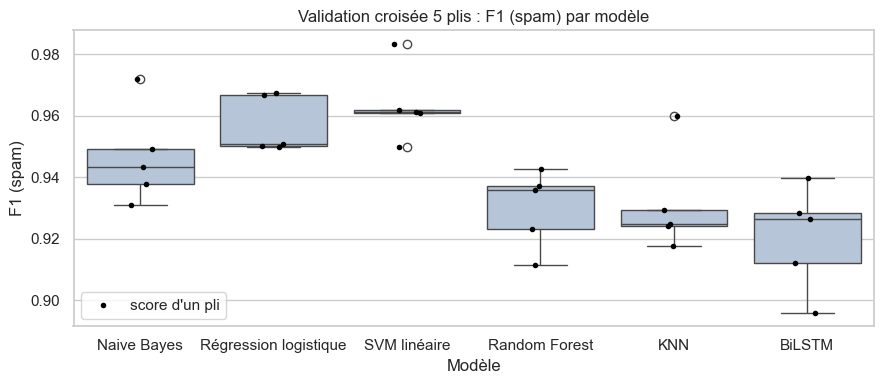

In [21]:
fig = U.plot_cv_boxplot(cv_f1_folds); save(fig, "07_cv_boxplot"); plt.show()

,Accuracy,Précision (spam),Rappel (spam),F1 (spam),F1 macro,ROC-AUC,PR-AUC
Modèle,,,,,,,
Naive Bayes,0.9936,0.9895,0.9592,0.9741,0.9852,0.9919,0.9882
Régression logistique,0.9884,0.9588,0.9490,0.9538,0.9736,0.9940,0.9879
BiLSTM,0.9871,0.9231,0.9796,0.9505,0.9715,0.9940,0.9833
SVM linéaire,0.9871,0.9490,0.9490,0.9490,0.9708,0.9949,0.9881
Random Forest,0.9845,0.9886,0.8878,0.9355,0.9633,0.9967,0.9847
KNN,0.9845,0.9886,0.8878,0.9355,0.9633,0.9930,0.9850


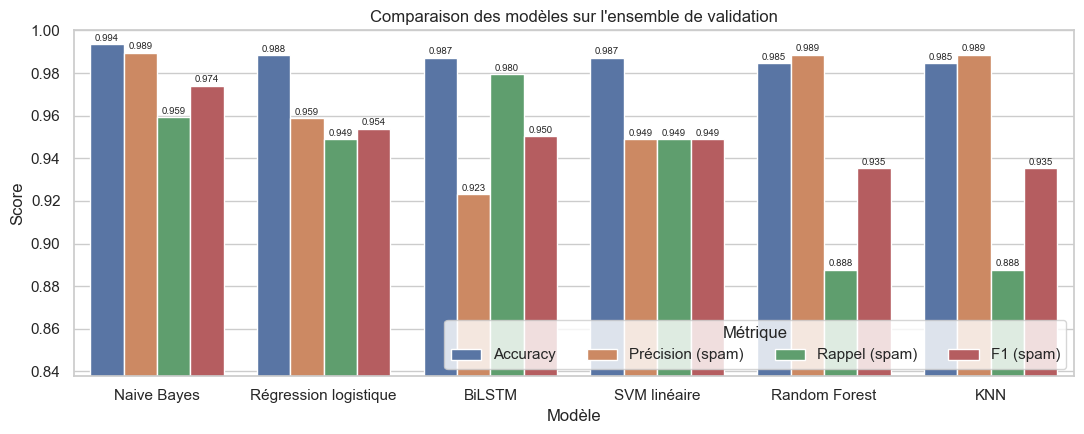

In [22]:
val_df = pd.DataFrame(val_rows).T.rename_axis("Modèle").sort_values("F1 (spam)", ascending=False)
display(val_df.round(4))
fig = U.plot_model_comparison(val_df, title="Comparaison des modèles sur l'ensemble de validation")
save(fig, "08_comparaison_validation"); plt.show()

In [23]:
# Critère : F1 (spam) moyen en validation croisée + F1 sur la validation (moyenne des deux)
sel = (cv_df["CV f1 (moy)"] + val_df["F1 (spam)"]) / 2
BEST = sel.idxmax()
print(sel.sort_values(ascending=False).round(4))
print("\nModèle retenu :", BEST)

Modèle
Naive Bayes              0.9604
SVM linéaire             0.9562
Régression logistique    0.9554
BiLSTM                   0.9355
KNN                      0.9333
Random Forest            0.9327
dtype: float64

Modèle retenu : Naive Bayes


## 7. Évaluation finale sur l'ensemble de test
Chaque modèle est réentraîné sur **train + validation** avec ses meilleurs hyperparamètres, puis
évalué une seule fois sur le test (données jamais vues).

,Accuracy,Précision (spam),Rappel (spam),F1 (spam),F1 macro,ROC-AUC,PR-AUC
Modèle,,,,,,,
SVM linéaire,0.9936,0.9895,0.9592,0.9741,0.9852,0.9972,0.9892
Régression logistique,0.9923,0.9792,0.9592,0.9691,0.9823,0.9969,0.9886
Random Forest,0.9910,1.0000,0.9286,0.9630,0.9789,0.9987,0.9928
Naive Bayes,0.9897,0.9688,0.9490,0.9588,0.9764,0.9921,0.9798
KNN,0.9832,0.9885,0.8776,0.9297,0.9601,0.9924,0.9819
BiLSTM,0.9781,0.8649,0.9796,0.9187,0.9530,0.9954,0.9862


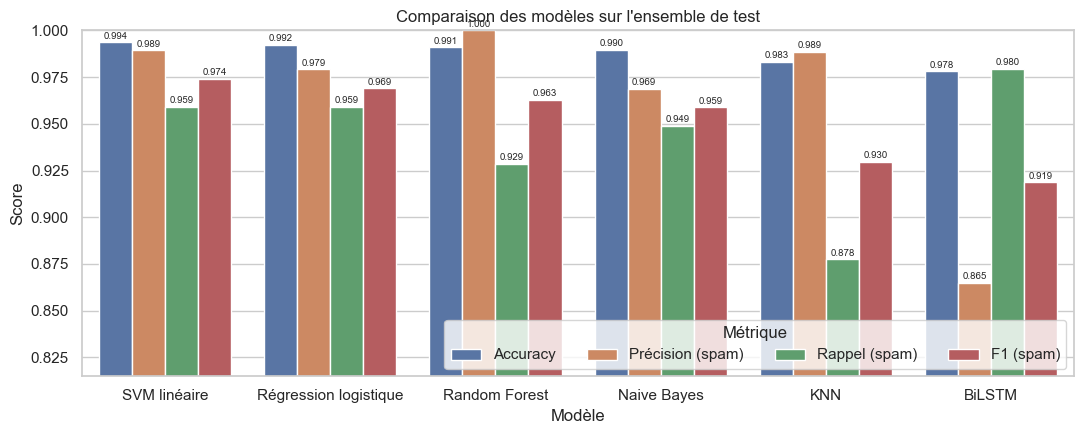

In [24]:
from sklearn.base import clone
X_trva = np.r_[X_tr, X_va]; y_trva = np.r_[y_tr, y_va]
test_rows, test_scores, test_preds, final_models = {}, {}, {}, {}
for name, est in best_models.items():
    m = clone(est).fit(X_trva, y_trva)
    final_models[name] = m
    test_preds[name] = m.predict(X_te)
    test_scores[name] = get_scores(m, X_te)
    test_rows[name] = U.compute_metrics(y_te, test_preds[name], test_scores[name])

# BiLSTM : vocabulaire sur train+val, arrêt précoce au nombre d'epochs trouvé précédemment
v_all = Vocab(X_trva, min_freq=2)
S_trva, S_te2 = v_all.encode(X_trva, MAXLEN), v_all.encode(X_te, MAXLEN)
# patience=None : pas d'arrêt précoce, nombre d'epochs fixé -> le test n'influence aucun choix
m, _ = train_bilstm(S_trva, y_trva, S_trva[:200], y_trva[:200], len(v_all),
                    epochs=hist["best_epoch"], patience=None, **best_dl)
p, pr = predict_bilstm(m, S_te2)
final_models["BiLSTM"] = m
test_scores["BiLSTM"], test_preds["BiLSTM"] = p, pr
test_rows["BiLSTM"] = U.compute_metrics(y_te, pr, p)

test_df = pd.DataFrame(test_rows).T.rename_axis("Modèle").sort_values("F1 (spam)", ascending=False)
display(test_df.round(4))
fig = U.plot_model_comparison(test_df, title="Comparaison des modèles sur l'ensemble de test")
save(fig, "09_comparaison_test"); plt.show()

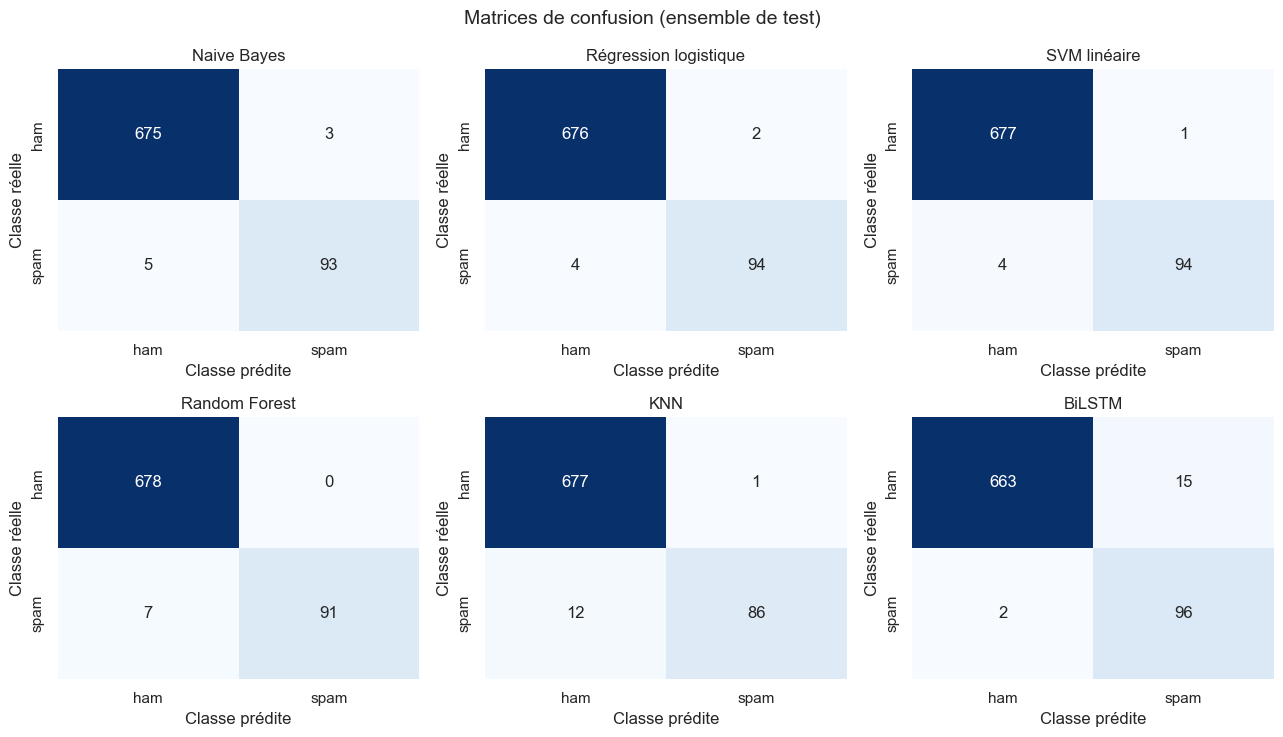

In [25]:
names = list(test_preds)
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, n in zip(axes.ravel(), names):
    U.plot_confusion(y_te, test_preds[n], n, ax=ax)
fig.suptitle("Matrices de confusion (ensemble de test)", fontsize=14)
plt.tight_layout(); save(fig, "10_matrices_confusion"); plt.show()

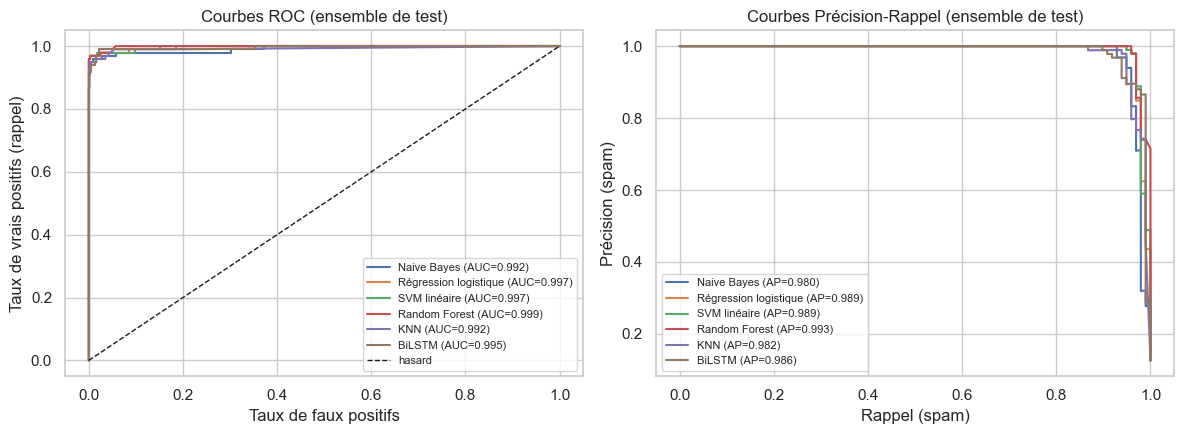

In [26]:
fig = U.plot_roc_pr({n: (y_te, s) for n, s in test_scores.items()}); save(fig, "11_roc_pr"); plt.show()

## 8. Courbes d'apprentissage
Score F1 (spam) en entraînement et en validation croisée selon la quantité de données.
Un grand écart persistant indique du **sur-apprentissage** ; deux courbes basses et proches
indiqueraient du **sous-apprentissage**.

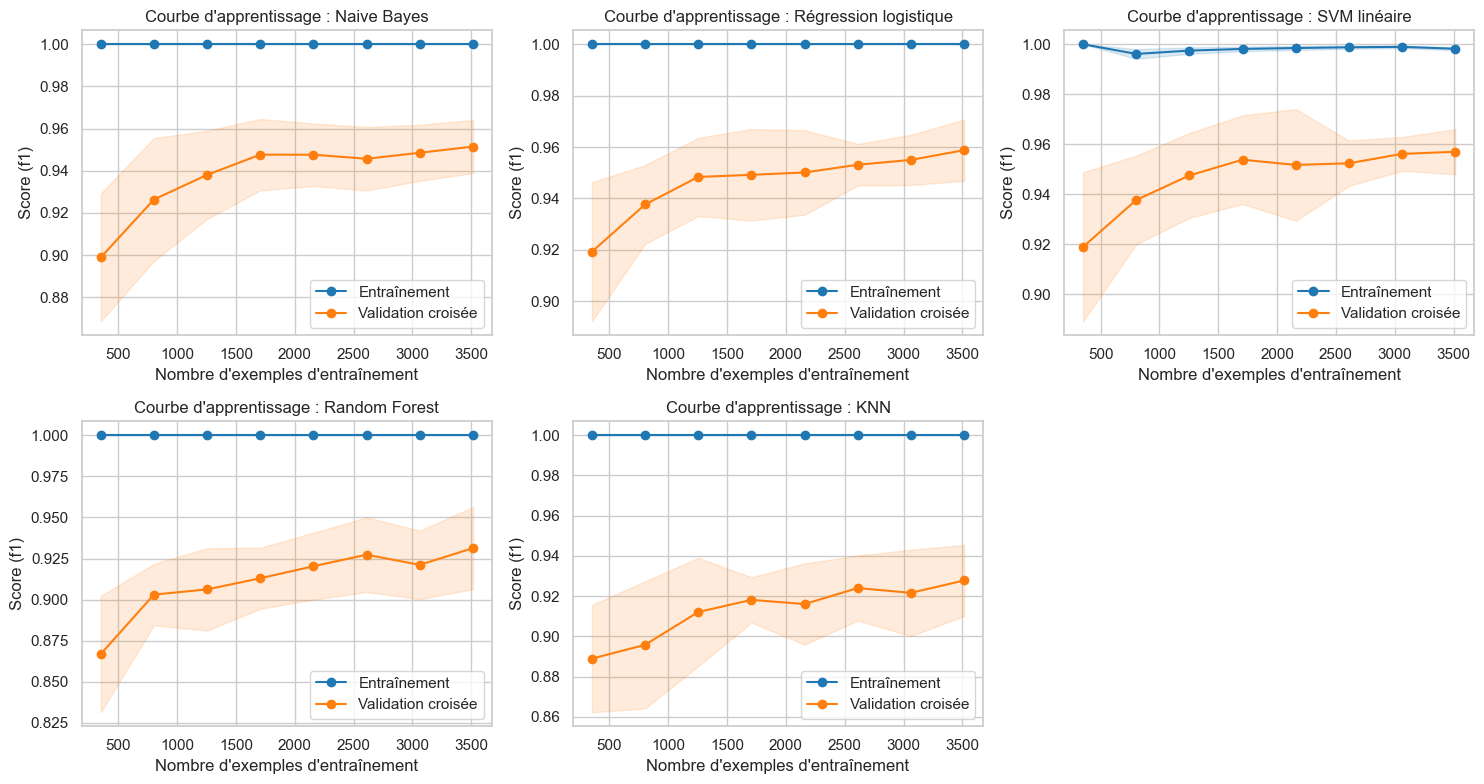

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, name in zip(axes.ravel(), best_models):
    U.plot_learning_curve(best_models[name], X_trva, y_trva, f"Courbe d'apprentissage : {name}", CV, ax=ax)
axes.ravel()[-1].axis("off")
plt.tight_layout(); save(fig, "12_courbes_apprentissage"); plt.show()

## 9. Importance des attributs

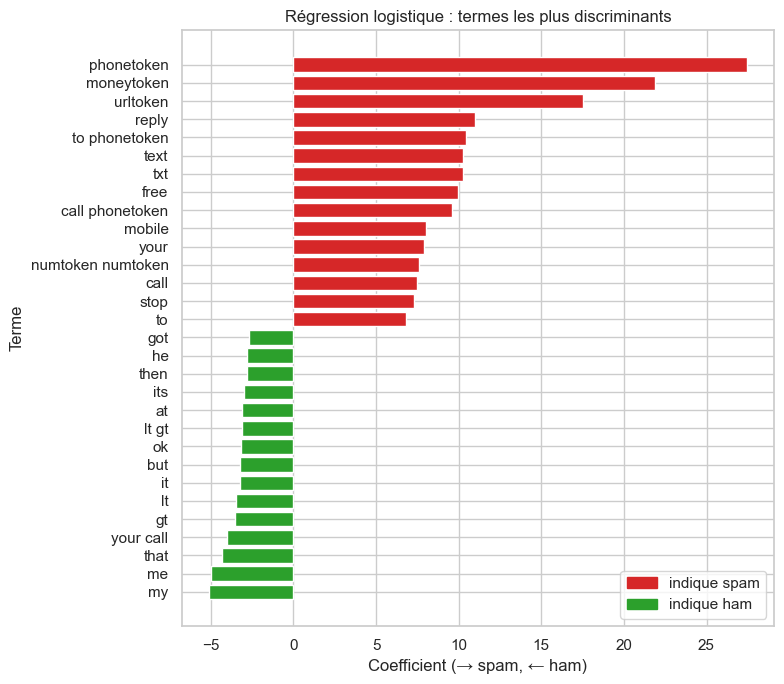

In [28]:
lr = final_models["Régression logistique"]
fn = lr.named_steps["tfidf"].get_feature_names_out()
fig = U.plot_top_coefficients(fn, lr.named_steps["clf"].coef_.ravel(),
                              "Régression logistique : termes les plus discriminants")
save(fig, "13_coefficients_lr"); plt.show()

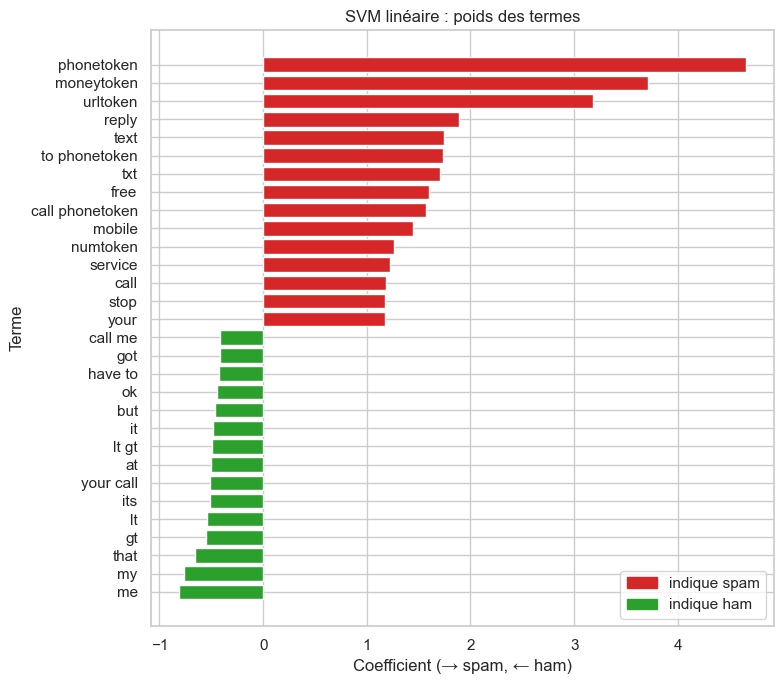

In [29]:
svm = final_models["SVM linéaire"]
fig = U.plot_top_coefficients(svm.named_steps["tfidf"].get_feature_names_out(),
                              svm.named_steps["clf"].coef_.ravel(), "SVM linéaire : poids des termes")
save(fig, "14_coefficients_svm"); plt.show()

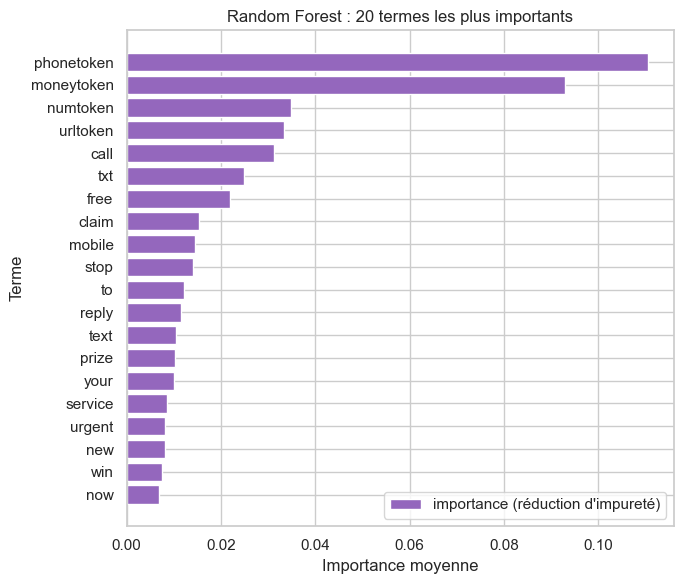

In [30]:
rf = final_models["Random Forest"]
fig = U.plot_importances(rf.named_steps["tfidf"].get_feature_names_out(),
                         rf.named_steps["clf"].feature_importances_,
                         "Random Forest : 20 termes les plus importants")
save(fig, "15_importance_rf"); plt.show()

## 10. Analyse des erreurs du modèle retenu
- **Faux négatifs** (spam non détecté) : le spam atteint l'utilisateur.
- **Faux positifs** (ham classé spam) : un message légitime est perdu, erreur la plus coûteuse
  pour l'utilisateur.

In [31]:
print("Modèle analysé :", BEST)
err = test[["message", "y"]].copy()
err["pred"] = test_preds[BEST]
err["score"] = test_scores[BEST]
err["n_chars"] = err["message"].str.len()
fp = err[(err.y == 0) & (err.pred == 1)]
fn_ = err[(err.y == 1) & (err.pred == 0)]
print(f"Faux positifs : {len(fp)}   Faux négatifs : {len(fn_)}   (sur {len(err)} SMS de test)")
print("\n--- Faux positifs (ham -> spam) ---")
display(fp.sort_values("score", ascending=False)[["message", "score"]])
print("\n--- Faux négatifs (spam -> ham) ---")
display(fn_.sort_values("score")[["message", "score", "n_chars"]])

Modèle analysé : Naive Bayes
Faux positifs : 3   Faux négatifs : 5   (sur 776 SMS de test)

--- Faux positifs (ham -> spam) ---


,message,score
221,Dont you have message offer,0.727101
48,Unlimited texts. Limited minutes.,0.657931
86,K:)eng rocking in ashes:),0.642298



--- Faux négatifs (spam -> ham) ---


,message,score,n_chars
599,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",0.002049,146
592,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,0.003046,152
180,"Latest News! Police station toilet stolen, cops have nothing to go on!",0.038662,70
151,Missed call alert. These numbers called but left no message. 07008009200,0.087847,72
1,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,0.259621,158


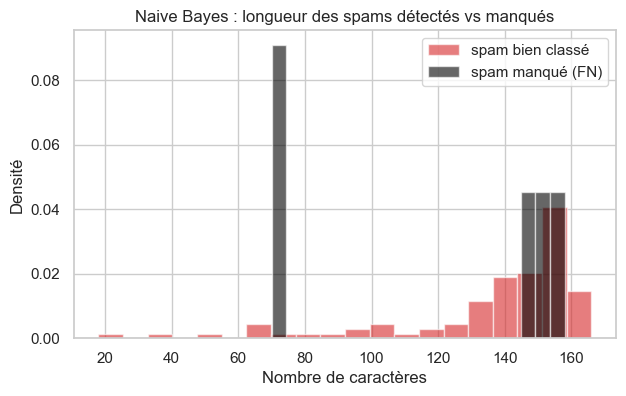

Longueur médiane — spams détectés : 148.0 | spams manqués : 146.0


In [32]:
fig, ax = plt.subplots(figsize=(7, 4))
ok = err[err.y == err.pred]
for d, lab, c in [(ok[ok.y == 1], "spam bien classé", "tab:red"), (fn_, "spam manqué (FN)", "black")]:
    ax.hist(d["n_chars"], bins=20, alpha=0.6, label=lab, color=c, density=True)
ax.set(title=f"{BEST} : longueur des spams détectés vs manqués", xlabel="Nombre de caractères",
       ylabel="Densité")
ax.legend(); save(fig, "16_erreurs_longueur"); plt.show()
print("Longueur médiane — spams détectés :", ok[ok.y == 1].n_chars.median(),
      "| spams manqués :", fn_.n_chars.median())

In [33]:
# Sauvegarde des tableaux pour le rapport
Path("resultats").mkdir(exist_ok=True)
cv_df.round(4).to_csv("resultats/cv.csv"); val_df.round(4).to_csv("resultats/validation.csv")
test_df.round(4).to_csv("resultats/test.csv"); pd.DataFrame(grid_info).T.to_csv("resultats/hyperparametres.csv")
dl_res.round(4).to_csv("resultats/bilstm_grille.csv", index=False)
print("Tableaux enregistrés dans Code/resultats/, figures dans Code/figures/")

Tableaux enregistrés dans Code/resultats/, figures dans Code/figures/


## 11. Conclusion

**Synthèse**
- Après suppression de 403 doublons (7,2 %), 5 171 SMS ont été répartis 70/15/15 de façon stratifiée (12,6 % de spam).
- Les **modèles linéaires sur TF-IDF (unigrammes + bigrammes)** dominent : SVM linéaire (F1-CV = 0,963), régression logistique (0,957) et Naive Bayes (0,947).
- **Modèle retenu (critère fixé avant le test : moyenne F1-CV + F1-validation) : Naive Bayes** (α = 0,05). Sur le test : F1 = 0,959, précision = 0,969, rappel = 0,949, 3 faux positifs et 5 faux négatifs sur 776 SMS.
- Sur le test, le **SVM linéaire** obtient le meilleur F1 (0,974). L'écart entre les trois modèles linéaires (≈ 0,01) est du même ordre que l'écart-type de la validation croisée (0,008 à 0,014) : ils sont **statistiquement équivalents**. Le SVM est un choix tout aussi défendable, avec un F1-CV plus élevé et plus stable.
- **Random Forest** et **KNN** ont une précision quasi parfaite (≈ 0,99 à 1,0) mais un rappel plus faible (≈ 0,88 à 0,93) : ils sont conservateurs.
- Le **BiLSTM** a le meilleur rappel (0,98) mais la plus faible précision (0,86). La pondération `pos_weight` le pousse à signaler davantage de spam. Avec environ 3 600 exemples, l'apprentissage profond n'apporte pas de gain par rapport à TF-IDF + modèle linéaire.

**Forces et faiblesses**
- Les courbes d'apprentissage montrent un score d'entraînement ≈ 1 et un score de validation qui monte encore à 3 500 exemples : **davantage de données** aiderait encore. La variance est modérée.
- Les termes les plus associés au spam sont les jetons de normalisation `phonetoken`, `moneytoken` et `urltoken`, puis `reply`, `txt`, `free`, `mobile`, `stop`. Ce résultat valide le choix de remplacer numéros, montants et URLs par des jetons plutôt que de les supprimer. Côté ham, on trouve des mots personnels (`my`, `me`, `that`) et `lt gt`, un reste de l'entité HTML `&lt;#&gt;` présente dans le corpus.
- Erreurs : les spams manqués sont des spams **sans indice lexical habituel** (quiz, contenu adulte, fausse « news »). Les faux positifs sont des SMS légitimes au vocabulaire commercial (« offer », « unlimited texts »).

**Améliorations futures**
- Ajuster le seuil de décision selon le coût d'un faux positif.
- Ajouter des attributs méta (longueur, ratio de majuscules) et des n-grammes de caractères (robustes aux fautes et à l'argot SMS).
- Utiliser des modèles pré-entraînés (DistilBERT) ou des embeddings pré-entraînés pour le LSTM.
- Faire un test statistique (McNemar) entre les meilleurs modèles et valider sur un corpus plus récent.
